In [10]:
import numpy as np
import matplotlib.pyplot as plt
from torchdiffeq import odeint
import sklearn.datasets as skld
import torch
import torch.nn as nn
from torch.nn import functional as F

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cuda


We start by constructing the velocity field with conditional probability path.

In [3]:
# get velocity field u_t(x|x_1)
def conditional_field(position, time, target, sigmin):
    return (target-(1-sigmin)*position)/(1-(1-sigmin)*time)

# get flow psi_t(x)
def conditional_sample(noise, time, target, sigmin):
    sigma = 1-(1-sigmin)*time
    mean = time*target
    return sigma*noise + mean

## 1-D Flow Matching


In [ ]:
Sigmin = 0.01 # sigma_min

### Visualization of a conditional field in 1D

Let's see how a conditional field with one target looks like:

(-1.0, 1.0)

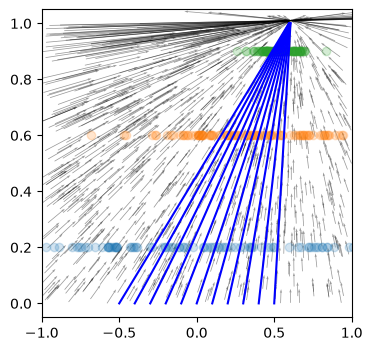

In [ ]:
Target = 0.6 # x_1 for conditional FM

# get random coordinates of the velocity field
def get_batch(N=1000):
    positions = np.random.uniform(-1, 1, N)
    times = np.random.uniform(0, 1, N)
    xt = np.column_stack([positions, times])
    return xt

# generate coordinates of the velocity field
xt = get_batch(1000)
target = np.full_like(xt[:,0], Target) # generate a list of the same target
field_test = conditional_field(xt[:,0], xt[:,1], target, Sigmin) # construct a cond field
plt.quiver(xt[:,0], xt[:,1], field_test, np.ones_like(field_test), angles='xy', scale_units = 'xy', scale = 20, alpha = 0.4)

# calculate examples of cond probability paths with odeint
tint = np.linspace(0.0,1.0)
xint = odeint(lambda t, x:conditional_field(x, t, Target, Sigmin), torch.tensor(np.linspace(-0.5,0.5,11).reshape(-1, 1)), torch.tensor(tint))
xint, tint = np.broadcast_arrays(xint, tint.reshape(-1,1,1)) # broadcasting extends tint from (50,1,1) to (50,11,1), matching xint
plt.plot(xint[...,0], tint[...,0], c='b') # plot cond prob paths

# draw samples at different times
noise = torch.randn(100)
for t in [0.2, 0.6, 0.9]:
    sample = conditional_sample(noise, t, Target, Sigmin)
    plt.scatter(sample, np.full_like(sample, t), alpha=0.2)

plt.gcf().set_size_inches(4,4)
plt.xlim(-1, 1)

### Training

In [ ]:
def sample_data(N=100):
    return torch.tensor(np.random.normal(loc=np.random.choice([-0.5, 0, 0.5], size=N),
                                          scale=0.1), device=device)

def mlp(hidden=128):
    return torch.nn.Sequential(
        torch.nn.Linear(2,hidden),
        torch.nn.ReLU(),
        torch.nn.Linear(hidden,hidden),
        torch.nn.ReLU(),
        torch.nn.Linear(hidden,1)
    ).to(device)

def train(model:torch.nn.Sequential):
    opt = torch.optim.Adam(model.parameters(), 1e-3)

    for i in range(10000):
        batch_size = 1000

        target = sample_data(batch_size)
        times = torch.rand(batch_size, device=device)
        positions = conditional_sample(torch.randn(batch_size, device=device), times, target, Sigmin)
        xt = torch.column_stack([positions, times])

        model_field = model(torch.tensor(xt, dtype=torch.float32))[:,0]
        cond_field = torch.tensor(conditional_field(xt[:,0], xt[:,1], target, Sigmin), dtype=torch.float32)
        loss = torch.nn.functional.mse_loss(model_field, cond_field)        
        
        loss.backward()
        opt.step()
        opt.zero_grad()
        if i % 1000 == 0:
            xt_np = xt.detach().cpu().numpy()
            cond_field_np = cond_field.detach().cpu().numpy()
            model_field_np = model_field.detach().cpu().numpy()
            plt.quiver(xt_np[:,0],xt_np[:,1], cond_field_np,np.ones_like(cond_field_np), angles = 'xy', scale_units = 'xy', scale = 20, alpha = 0.4, color = 'black')
            plt.quiver(xt_np[:,0],xt_np[:,1], model_field_np,np.ones_like(model_field_np), angles = 'xy', scale_units = 'xy', scale = 20, alpha = 0.4, color = 'maroon')
            plt.gcf().set_size_inches(4,4)
            plt.xlim(-1,1)
            plt.show()
    return model


/tmp/ipykernel_3783801/1724711084.py:25: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  model_field = model(torch.tensor(xt, dtype=torch.float32))[:,0]
/tmp/ipykernel_3783801/1724711084.py:26: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  cond_field = torch.tensor(conditional_field(xt[:,0], xt[:,1], target, Sigmin), dtype=torch.float32)


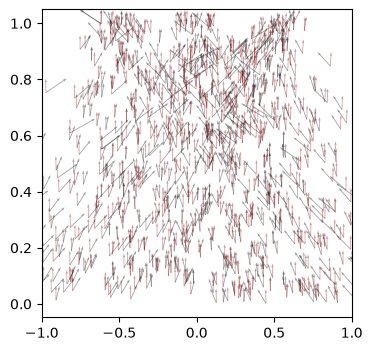

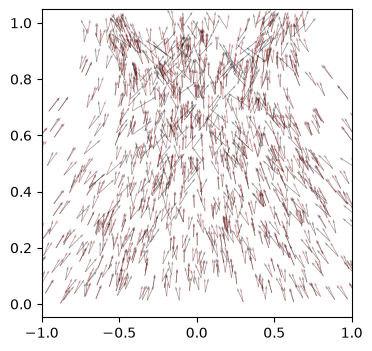

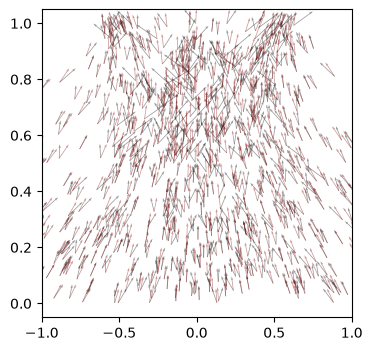

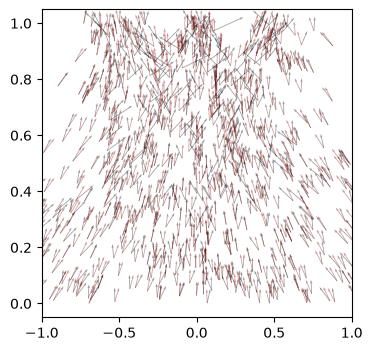

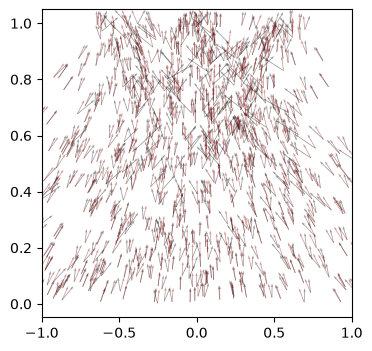

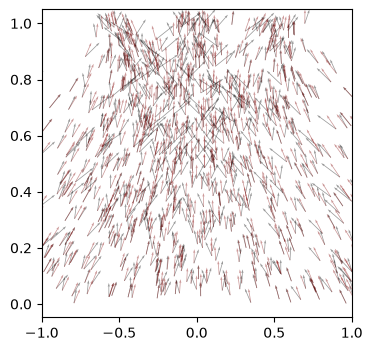

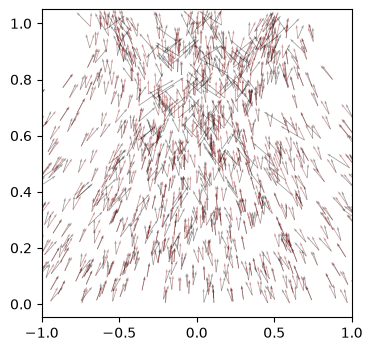

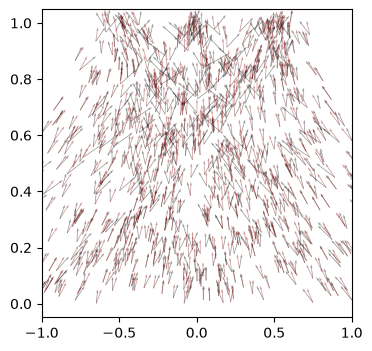

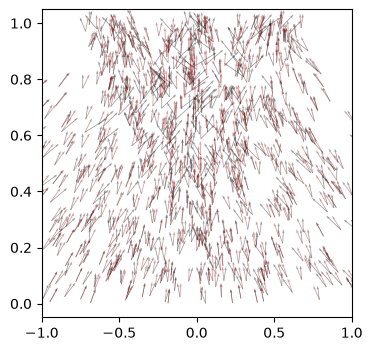

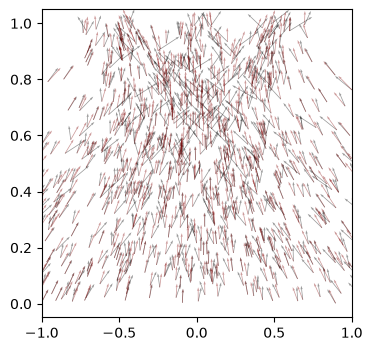

In [ ]:
model = mlp()

model = model.train()
model = train(model)

### Model Evaluaion

In [ ]:
model = model.eval()

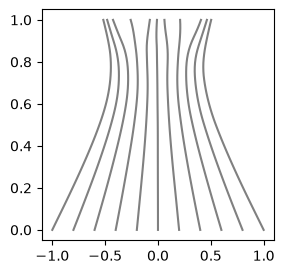

In [ ]:
with torch.no_grad():
    tint = np.linspace(0.0,1.0)
    xint = odeint(lambda t, x:model(torch.cat([x,torch.full(x.shape, t.item(), device=device)], dim=-1).float()),
                torch.tensor(np.linspace(-1,1,11).reshape(-1, 1), device=device), torch.tensor(tint, device=device))
    xint, tint = np.broadcast_arrays(xint.detach().cpu().numpy(), tint.reshape(-1,1,1))
    plt.plot(xint[...,0], tint[...,0], c='grey')
    plt.gcf().set_size_inches(3,3)

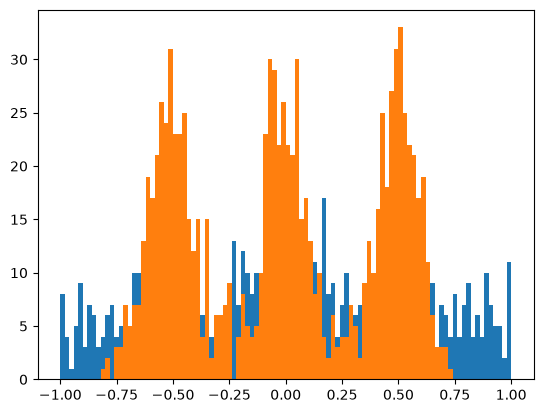

In [ ]:
with torch.no_grad():
    tint = torch.tensor([0.0,1.0], dtype=torch.float32, device=device)
    noise = torch.randn(1000,1, device=device)
    xint = odeint(lambda t,x: model(torch.cat([x,torch.full(x.shape, t.item(), device=device)],dim=-1).float()).detach(), noise, tint)
    bins = np.linspace(-1,1,101)
    plt.hist(xint[0,::,-1].detach().cpu().numpy(), bins = bins)
    plt.hist(xint[-1,::,-1].detach().cpu().numpy(), bins = bins)

(array([ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  1.,
         1.,  5.,  6.,  9.,  7.,  9., 13., 12., 24., 20., 23., 29., 26.,
        14., 18., 21., 17., 21., 11., 16.,  7.,  1.,  3.,  0.,  4.,  4.,
         2.,  4.,  6.,  7., 12.,  9., 16., 24., 24., 37., 37., 22., 29.,
        28., 26., 18., 11., 13., 10.,  6.,  5.,  3.,  2.,  2.,  3.,  1.,
         7.,  5.,  8., 10., 11., 10., 27., 22., 17., 32., 30., 19., 26.,
        22., 19., 14., 14., 14.,  4.,  5.,  2.,  0.,  0.,  1.,  0.,  0.,
         1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.]),
 array([-1.  , -0.98, -0.96, -0.94, -0.92, -0.9 , -0.88, -0.86, -0.84,
        -0.82, -0.8 , -0.78, -0.76, -0.74, -0.72, -0.7 , -0.68, -0.66,
        -0.64, -0.62, -0.6 , -0.58, -0.56, -0.54, -0.52, -0.5 , -0.48,
        -0.46, -0.44, -0.42, -0.4 , -0.38, -0.36, -0.34, -0.32, -0.3 ,
        -0.28, -0.26, -0.24, -0.22, -0.2 , -0.18, -0.16, -0.14, -0.12,
        -0.1 , -0.08, -0.06, -0.04, -0.02,  0.  ,  0.02,  0.04,  0.06,
        

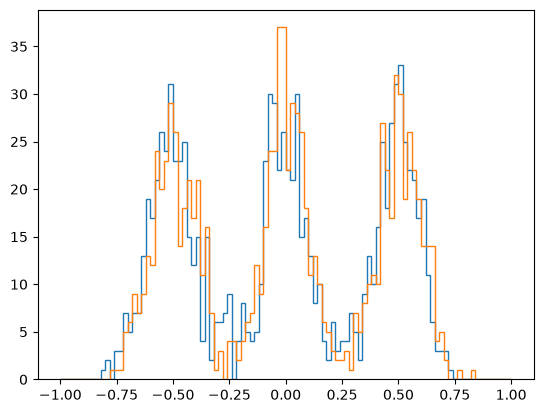

In [ ]:
plt.hist(xint[-1,::,-1].detach().cpu().numpy(), bins = bins, histtype = 'step')
plt.hist(np.random.normal(loc=np.random.choice([-0.5, 0, 0.5], size=1000), scale=0.1), bins = bins, histtype='step')


In [ ]:
print("Model:", next(model.parameters()).device)
print("CUDA memory allocated:",
      torch.cuda.memory_allocated() / 1024**2, "MB")

Model: cuda:0
CUDA memory allocated: 16.861328125 MB


## 2-D FLow Matching

In [4]:
Sigmin_2d = torch.tensor([0.01, 0.01], device=device)

def sample_data_2d(N=100):
    return torch.tensor(skld.make_moons(N, noise=0.05)[0], dtype=torch.float32, device=device)

### MLP-based model

#### Training

In [5]:
def mlp_2d(hidden=128):
    return torch.nn.Sequential(
        torch.nn.Linear(3,hidden),
        torch.nn.ReLU(),
        torch.nn.Linear(hidden,hidden),
        torch.nn.ReLU(),
        torch.nn.Linear(hidden,2)
    ).to(device)

def train_2d(model:torch.nn.Sequential):
    opt = torch.optim.Adam(model.parameters(), 1e-3)

    for i in range(20000):
        batch_size = 1000

        target = sample_data_2d(batch_size)
        times = torch.rand(batch_size, 1, device=device)
        positions = conditional_sample(torch.randn(batch_size, 2, device=device), times, target, Sigmin_2d)
        xt = torch.column_stack([positions, times])

        model_field = model(torch.tensor(xt, dtype=torch.float32))
        cond_field = torch.tensor(conditional_field(xt[:,:-1], xt[:,-1:], target, Sigmin_2d), dtype=torch.float32)
        loss = torch.nn.functional.mse_loss(model_field, cond_field)
        
        loss.backward()
        opt.step()
        opt.zero_grad()
        if i % 1000 == 0:
            print(i, float(loss))
    return model

In [20]:
model_2d = mlp_2d()

model_2d.train()
model_2d = train_2d(model_2d)

/tmp/ipykernel_977910/1749279514.py:21: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  model_field = model(torch.tensor(xt, dtype=torch.float32))
/tmp/ipykernel_977910/1749279514.py:22: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  cond_field = torch.tensor(conditional_field(xt[:,:-1], xt[:,-1:], target, Sigmin_2d), dtype=torch.float32)
/tmp/ipykernel_977910/1749279514.py:29: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  print(i, float(loss))


0 1.7600840330123901
1000 1.018477201461792
2000 0.9327040314674377
3000 0.9196465611457825
4000 0.9307668805122375
5000 0.9212563037872314
6000 0.89933842420578
7000 0.9689810276031494
8000 0.9418488144874573
9000 0.9872134923934937
10000 0.9451404809951782
11000 0.9571417570114136
12000 0.9249343872070312
13000 0.9093424081802368
14000 0.9716777801513672
15000 0.8434690833091736
16000 0.938816487789154
17000 0.952757716178894
18000 0.9500725269317627
19000 0.9733552932739258


#### Visualization

In [21]:
with torch.no_grad():
    tint = torch.linspace(0.0,1.0,21)
    xint = odeint(lambda t, x:model_2d(torch.cat([x,torch.full((len(x), 1), t.item(), device=device)], dim=-1)),
                torch.tensor(torch.randn(1000,2), device=device), torch.tensor(tint, device=device))
    xint = xint.cpu().numpy()

/tmp/ipykernel_977910/1795906032.py:4: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(torch.randn(1000,2), device=device), torch.tensor(tint, device=device))


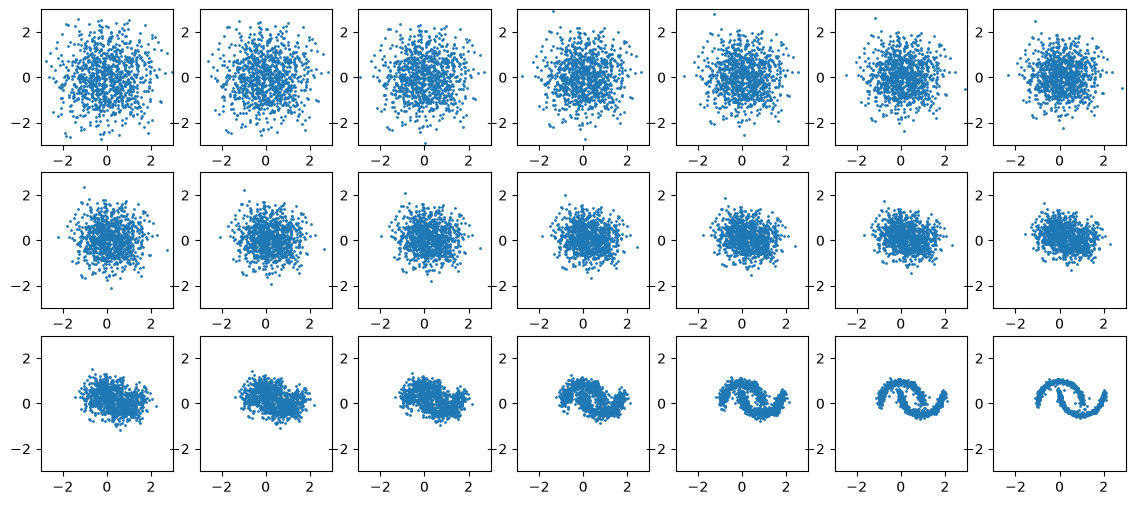

In [24]:
f, axarr = plt.subplots(3, 7, figsize=(14, 6))
for idx, ax in enumerate(axarr.ravel()):
    ax.scatter(xint[idx][:,0],xint[idx][:,1], s = 1)
    ax.set_xlim([-3,3])
    ax.set_ylim([-3,3])

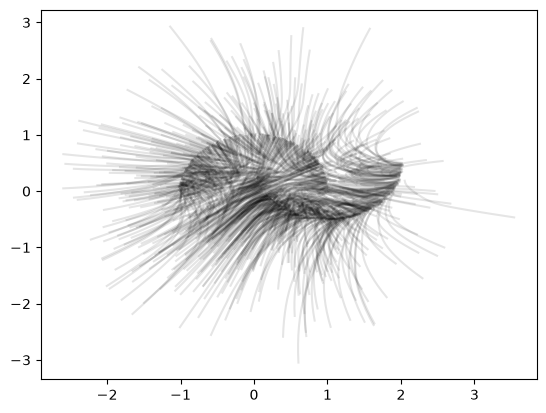

In [12]:
plt.plot(xint[:,:,0],xint[:,:,1],c = 'k', alpha = 0.1)

### Transformer FM

In [6]:
# hyperparameters
batch_size = 1000
learning_rate = 1e-3
max_iters = 10000
eval_interval = 100
n_embd = 64
n_head = 4
n_layer = 4
dropout = 0
# ------------

In [11]:
class Head(nn.Module):
    """ one head of self-attention """

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        k = self.key(x)   # (B,T,H), H = head_size
        q = self.query(x) # (B,T,H)
        B,T,head_size = k.shape
        # compute attention scores ("affinities")
        wei = q @ k.transpose(-2,-1) * head_size**-0.5 # (B, T, H) @ (B, H, T) -> (B, T, T)
        wei = F.softmax(wei, dim=-1) # (B, T, T)
        wei = self.dropout(wei)
        # perform the weighted aggregation of the values
        v = self.value(x) # (B,T,H)
        out = wei @ v # (B, T, T) @ (B, T, H) -> (B, T, H)
        return out

class MultiHeadAttention(nn.Module):
    """ multiple heads of self-attention in parallel """

    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out

class FeedFoward(nn.Module):
    """ a simple linear layer followed by a non-linearity """

    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    """ Transformer block: communication followed by computation """

    def __init__(self, n_embd, n_head):
        # n_embd: embedding dimension, n_head: the number of heads we'd like
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedFoward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x


class Encoder_Transformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding = nn.Linear(1, n_embd) # Since input is continuous, we use nn.Linear() instead of nn.Embedding()
        self.variable_embedding = nn.Embedding(3, n_embd) # Type of the token, (data[0], data[1], time)
        self.known_embedding = nn.Embedding(2, n_embd) # The flow should act different to the token, depending on if it's known
        self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd) # final layer norm
        self.vf_head = nn.Linear(n_embd, 1) # from embedding to velocity field

    def forward(self, idx, known=None):
        '''
        idx: (B, 3), Input[0] = [data[0], data[1], time]
        known: (2,) or (B, 2), List or torch.tensor, dtype = torch.bool
        '''
        B, T = idx.shape

        if known is None:
            known = torch.zeros((B, 2), dtype=torch.bool, device=device)
        else:
            known = torch.as_tensor(known, dtype=torch.bool, device=device)
            if known.ndim == 1:
                known = known.expand(B, -1)
        
        # B = batch_size, T = dim_input, C = embedding_dimension
        tok_emb = self.token_embedding(idx.unsqueeze(-1)) # (B,T,C)
        var_emb = self.variable_embedding(torch.arange(T, device=device)) # (T,C)

        # Append True for time dimension
        known_full = torch.cat([known, known.new_ones((B, 1))], dim=1)  # (B,T)
        kno_emb = self.known_embedding(known_full.long())  # (B,T,C)

        x = tok_emb + var_emb + kno_emb
        x = self.blocks(x) # (B,T,C)
        x = self.ln_f(x) # (B,T,C)

        logits = self.vf_head(x).squeeze(-1)[:, :-1]  # (B,2)
        logits = logits * (~known)

        return logits


In [12]:
masks = torch.tensor([
    [True, False],
    [False, True],
    [False, False],
], device=device)

In [13]:
# sanity check
m = Encoder_Transformer()
m = m.to(device)

input = torch.rand(16,3, device=device)
known = torch.tensor([False, True], device=device)
# known = masks[torch.randint(len(masks), (16,))]
output = m(input, known=known)
print(known[:10])
print(output[:10])
assert output.shape == (16, 2)

tensor([False,  True], device='cuda:0')
tensor([[-0.3051, -0.0000],
        [-0.1871, -0.0000],
        [-0.2154, -0.0000],
        [-0.4035, -0.0000],
        [-0.2204, -0.0000],
        [-0.3793, -0.0000],
        [-0.3795, -0.0000],
        [-0.1992, -0.0000],
        [-0.4304, -0.0000],
        [-0.4284, -0.0000]], device='cuda:0', grad_fn=<SliceBackward0>)


In [14]:
val_indices = torch.randint(len(masks), (batch_size,), device=device)
val_target = sample_data_2d(batch_size)
val_times = torch.rand(batch_size, 1, device=device)
val_noise = torch.randn(batch_size, 2, device=device)
val_batch = (val_indices, val_target, val_times, val_noise)

In [15]:
def train_val_loop(model, validation=False):

    if validation:
        indices, target, times, noise = val_batch
    else:
        indices = torch.randint(len(masks), (batch_size,), device=device)
        target = sample_data_2d(batch_size)
        times = torch.rand(batch_size, 1, device=device)
        noise = torch.randn(batch_size, 2, device=device)

    known_masks = masks[indices]
    positions = conditional_sample(noise, times, target, Sigmin_2d)
    cond_field = conditional_field(positions, times, target, Sigmin_2d)
    positions = torch.where(known_masks, target, positions)

    xt = torch.column_stack([positions, times])
    model_field = model(xt, known=known_masks)

    unknown = ~known_masks
    loss = ((model_field - cond_field)**2 * unknown).sum() / unknown.sum()
    # loss = F.mse_loss(model_field, cond_field) # F.mse_loss can't handle known values

    return loss

In [16]:
def train_transformer_FM(model):
    opt = torch.optim.Adam(model.parameters(), learning_rate)

    loss_history = []
    for i in range(max_iters):

        loss = train_val_loop(model)
        
        loss.backward()
        opt.step()
        opt.zero_grad()
        if i % eval_interval == 0 or i == max_iters - 1:
            with torch.no_grad():
                model.eval()

                loss_val = train_val_loop(model, validation=True)
                loss_history.append([loss.item(), loss_val.item()])

                if i % eval_interval == 0:
                    print(f"step {i}: train loss {loss:.4f}, val loss {loss_val:.4f}")
                
                model.train()
    return model, loss_history


In [17]:

model_transformer = Encoder_Transformer()
model_transformer = model_transformer.to(device)

model_transformer.train()
model_transformer, loss_history = train_transformer_FM(model_transformer)

step 0: train loss 2.4617, val loss 1.8033
step 100: train loss 1.0390, val loss 1.0484
step 200: train loss 0.8468, val loss 0.8968
step 300: train loss 0.8598, val loss 0.8373
step 400: train loss 0.8232, val loss 0.8304
step 500: train loss 0.8220, val loss 0.8222
step 600: train loss 0.8228, val loss 0.8169
step 700: train loss 0.8057, val loss 0.8148
step 800: train loss 0.8086, val loss 0.8092
step 900: train loss 0.7677, val loss 0.8121
step 1000: train loss 0.8041, val loss 0.8019
step 1100: train loss 0.8035, val loss 0.8144
step 1200: train loss 0.7811, val loss 0.7923
step 1300: train loss 0.7646, val loss 0.7977
step 1400: train loss 0.7774, val loss 0.8127
step 1500: train loss 0.7884, val loss 0.8068
step 1600: train loss 0.7421, val loss 0.8095
step 1700: train loss 0.7989, val loss 0.7947
step 1800: train loss 0.8326, val loss 0.8008
step 1900: train loss 0.7710, val loss 0.7981
step 2000: train loss 0.8471, val loss 0.7954
step 2100: train loss 0.8222, val loss 0.8048


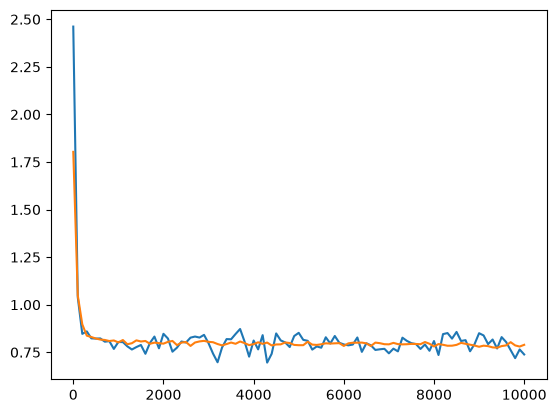

In [18]:
loss_history = torch.tensor(loss_history).cpu().detach().numpy()
plt.plot(np.arange(loss_history.shape[0])*eval_interval, loss_history[:,0])
plt.plot(np.arange(loss_history.shape[0])*eval_interval, loss_history[:,1])
plt.show()

/tmp/ipykernel_977910/313688399.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.randn(1000,2, device=device), torch.tensor(tint, device=device))


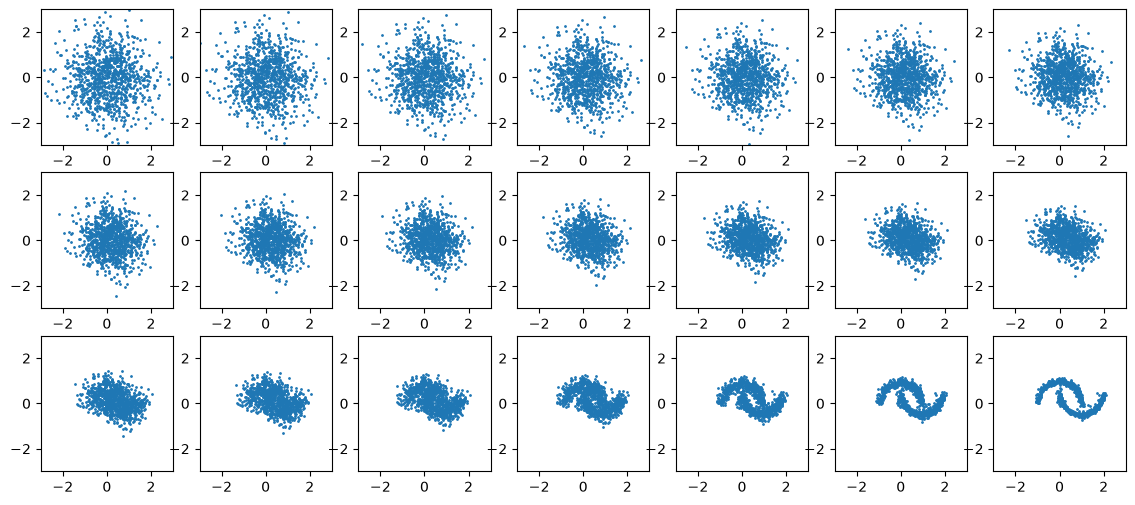

In [25]:
model_transformer.eval()
with torch.no_grad():
    tint = torch.linspace(0.0,1.0,21)
    xint = odeint(lambda t, x:model_transformer(torch.cat([x,torch.full((len(x), 1), t.item(), device=device)], dim=-1)),
                torch.randn(1000,2, device=device), torch.tensor(tint, device=device))
    xint = xint.cpu().numpy()

f, axarr = plt.subplots(3, 7, figsize=(14, 6))
for idx, ax in enumerate(axarr.ravel()):
    ax.scatter(xint[idx][:,0],xint[idx][:,1], s = 1)
    ax.set_xlim([-3,3])
    ax.set_ylim([-3,3])

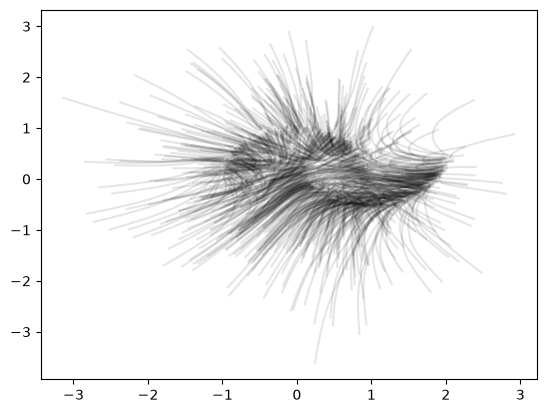

In [26]:
plt.plot(xint[:,:,0],xint[:,:,1],c = 'k', alpha = 0.1)

/tmp/ipykernel_977910/1557103325.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  positions, torch.tensor(tint, device=device))


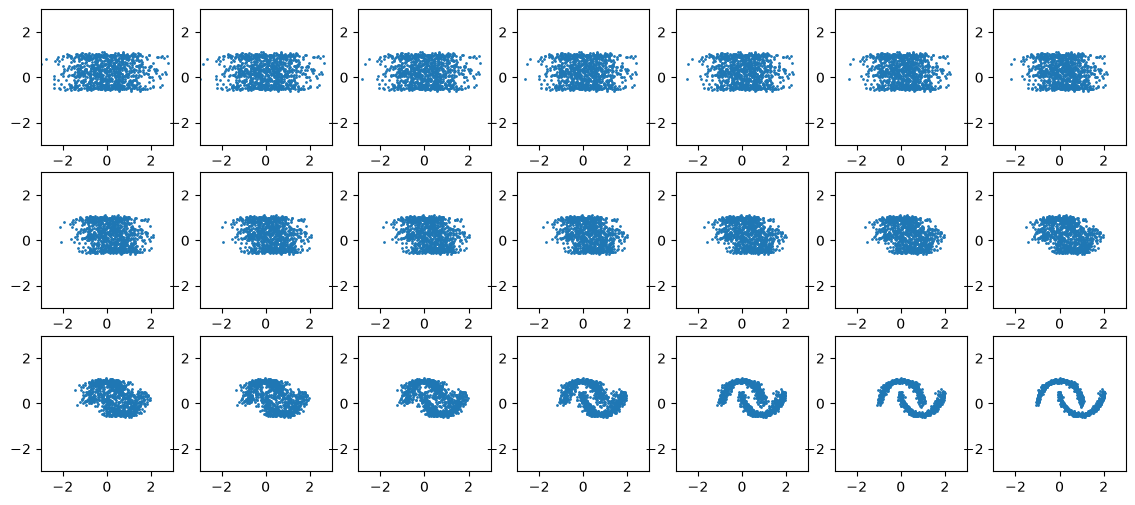

In [33]:
model_transformer.eval()
with torch.no_grad():
    tint = torch.linspace(0.0,1.0,21)
    known = [False, True]
    target = sample_data_2d(1000)[:,1].unsqueeze(-1)
    positions = torch.cat([torch.randn(1000,1, device=device),target],dim=-1)
    xint = odeint(lambda t, x:model_transformer(torch.cat([x,torch.full((len(x), 1), t.item(), device=device)], dim=-1), known=known),
                positions, torch.tensor(tint, device=device))
    xint = xint.cpu().numpy()

f, axarr = plt.subplots(3, 7, figsize=(14, 6))
for idx, ax in enumerate(axarr.ravel()):
    ax.scatter(xint[idx][:,0],xint[idx][:,1], s = 1)
    ax.set_xlim([-3,3])
    ax.set_ylim([-3,3])

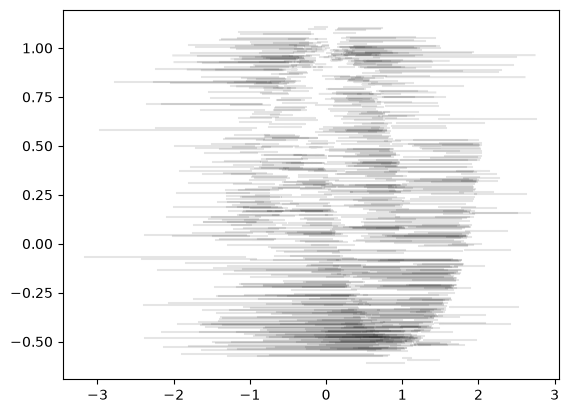

In [34]:
plt.plot(xint[:,:,0],xint[:,:,1],c = 'k', alpha = 0.1)

/tmp/ipykernel_977910/3401622986.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  positions, torch.tensor(tint, device=device))


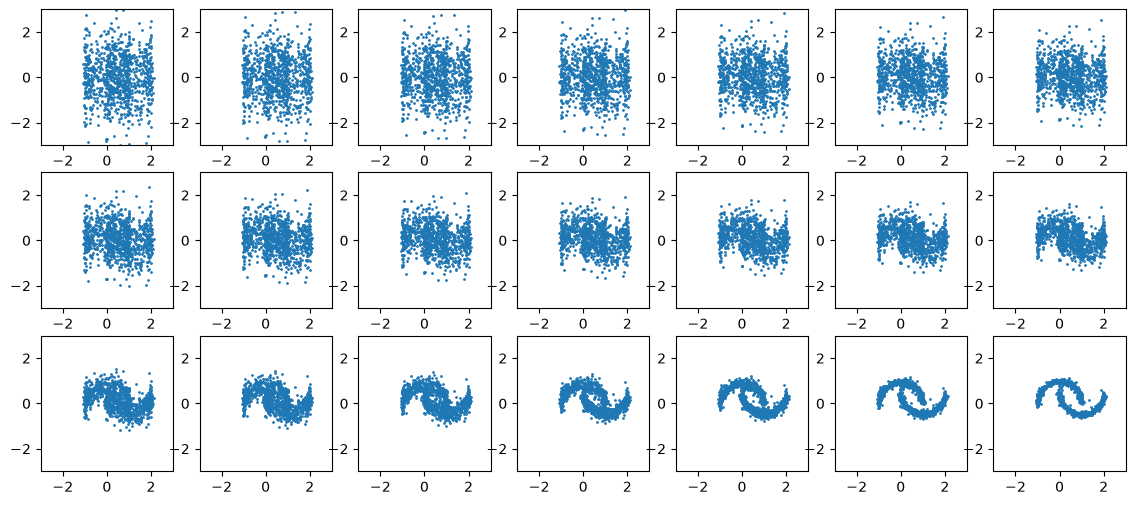

In [31]:
model_transformer.eval()
with torch.no_grad():
    tint = torch.linspace(0.0,1.0,21)
    known = [True, False]
    target = sample_data_2d(1000)[:,0].unsqueeze(-1)
    positions = torch.cat([target,torch.randn(1000,1, device=device)],dim=-1)
    xint = odeint(lambda t, x:model_transformer(torch.cat([x,torch.full((len(x), 1), t.item(), device=device)], dim=-1), known=known),
                positions, torch.tensor(tint, device=device))
    xint = xint.cpu().numpy()

f, axarr = plt.subplots(3, 7, figsize=(14, 6))
for idx, ax in enumerate(axarr.ravel()):
    ax.scatter(xint[idx][:,0],xint[idx][:,1], s = 1)
    ax.set_xlim([-3,3])
    ax.set_ylim([-3,3])

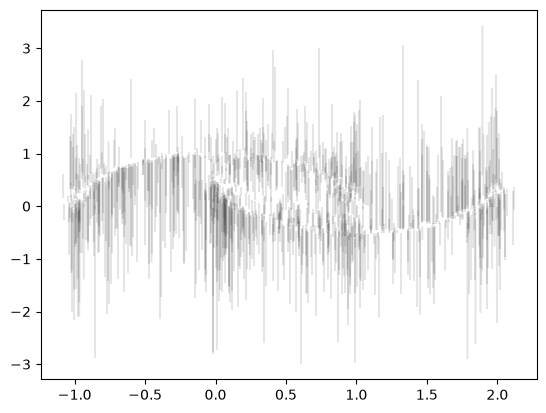

In [32]:
plt.plot(xint[:,:,0],xint[:,:,1],c = 'k', alpha = 0.1)